# PathSnap: five-model training and evaluation

This notebook trains **one model per model cell** using the same feature and evaluation functions as `train.py`. The saved outputs below come from a real run on the provided student dataset. No evaluator-test data is used.

**Label limitation:** `.route` is a sequence of road arcs, not a label for each GPS point. We create a proxy pointwise label by finding the nearest reference-route arc. All pointwise metrics below refer to that proxy.

## Shared setup

All models use the same 80 training trips, six candidates per GPS observation, at most 120 observations per training trip, and three-fold **GroupKFold** (whole trips stay together). Student-test evaluation uses ten trips with at most 250 observations per trip. The next cell prepares that shared data once. If your dataset is elsewhere, edit `DATA_ROOT`.

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
from train import collect, grouped_cv, score_model

DATA_ROOT = Path(os.environ.get("PATHSNAP_DATA_ROOT", "data"))
assert (DATA_ROOT / "train").is_dir() and (DATA_ROOT / "student_test").is_dir(), f"Dataset not found: {DATA_ROOT}"
with redirect_stdout(StringIO()):
    X_train, y_train, trip_groups, training_trip_items = collect(DATA_ROOT / "train", 120)
    _, _, _, test_trips = collect(DATA_ROOT / "student_test", 250)
del training_trip_items
print(f"80 training trips: {len(y_train):,} candidate rows; positive-label share: {y_train.mean():.2%}")
print(f"Student-test trips: {len(test_trips)}; candidate rows: {sum(len(t['labels'].ravel()) for t in test_trips):,}")
print("Proxy label = candidate arc equals nearest arc on the permitted reference route.")

C:\Users\athar\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


80 training trips: 57,600 candidate rows; positive-label share: 15.84%
Student-test trips: 10; candidate rows: 15,000
Proxy label = candidate arc equals nearest arc on the permitted reference route.


## EDA and GPS preprocessing

The same `clean_track` function in `pathsnap.py` runs whenever `Trip.load` is used for training, evaluation, or API prediction. It (1) discards missing, nonfinite, or out-of-range coordinates/times; (2) sorts by timestamp; (3) removes exact duplicate rows and conflicting observations at the same timestamp; and (4) removes observations requiring movement faster than **70 m/s (252 km/h)** from the last retained point. Repeated positions at different times are retained because a vehicle can stop. The plots below show actual raw-versus-cleaned data and removal counts, rather than assuming every cleaning rule found bad rows.

GPS quality audit across 90 trips


,observations
raw_points,227577
invalid_rows,0
duplicate_rows,0
timestamp_conflicts,0
timestamps_reordered,0
outlier_rows,177
clean_points,227400


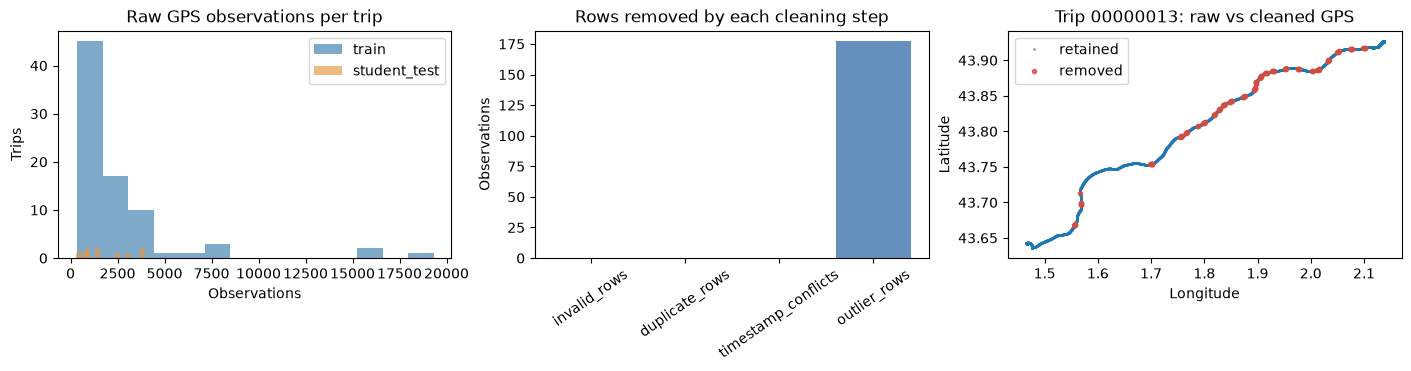

Cleaning uses the same 70 m/s speed cap in training and prediction.


In [2]:
from collections import Counter
from pathsnap import clean_track, MAX_GPS_SPEED_MPS

audit_rows = []
for partition in ("train", "student_test"):
    for path in sorted((DATA_ROOT / partition).glob("*/*.track")):
        raw = np.loadtxt(path, ndmin=2)
        cleaned, counts = clean_track(raw)
        audit_rows.append({"partition": partition, "trip": path.parent.name, **counts})
audit = pd.DataFrame(audit_rows)
totals = audit[["raw_points", "invalid_rows", "duplicate_rows", "timestamp_conflicts", "timestamps_reordered", "outlier_rows", "clean_points"]].sum()
print("GPS quality audit across", len(audit), "trips")
display(totals.rename("observations").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout="constrained")
for partition, color in (("train", "#397cad"), ("student_test", "#e7963c")):
    axes[0].hist(audit.loc[audit.partition == partition, "raw_points"], bins=14, alpha=.65, color=color, label=partition)
axes[0].set(title="Raw GPS observations per trip", xlabel="Observations", ylabel="Trips")
axes[0].legend()
counts = totals[["invalid_rows", "duplicate_rows", "timestamp_conflicts", "outlier_rows"]]
axes[1].bar(counts.index, counts.values, color="#658fbc")
axes[1].tick_params(axis="x", rotation=35)
axes[1].set(title="Rows removed by each cleaning step", ylabel="Observations")
example = audit.sort_values("outlier_rows", ascending=False).iloc[0]
example_path = DATA_ROOT / example.partition / example.trip / (example.trip + ".track")
raw = np.loadtxt(example_path, ndmin=2)
cleaned, _ = clean_track(raw)
retained = {tuple(row) for row in cleaned}
removed = np.asarray([row for row in raw if tuple(row) not in retained]).reshape(-1, 3)
axes[2].plot(cleaned[:, 0], cleaned[:, 1], ".", ms=2, alpha=.55, label="retained")
axes[2].plot(removed[:, 0], removed[:, 1], "o", ms=3, alpha=.8, color="#d14d43", label="removed")
axes[2].set(title=f"Trip {example.trip}: raw vs cleaned GPS", xlabel="Longitude", ylabel="Latitude")
axes[2].legend()
plt.show()
print(f"Cleaning uses the same {MAX_GPS_SPEED_MPS:.0f} m/s speed cap in training and prediction.")

## Metric helper

Each model cell below runs grouped CV, fits on the training rows, scores the student-test trips, displays **every recorded metric**, and plots its confusion matrix. Candidate accuracy/precision/recall/F1 are binary candidate-classification metrics. Top-1 and after-Viterbi accuracy are per-GPS proxy metrics. Higher is better except for log loss, candidate miss rate, and time.

In [3]:
model_results = {}

def evaluate_one_model(name, model):
    started = time.perf_counter()
    cv_scores = grouped_cv(model, X_train, y_train, trip_groups, folds=3)
    model.fit(X_train, y_train)
    training_seconds = time.perf_counter() - started
    metrics = score_model(model, test_trips)
    metrics["train_macro_f1"] = float(f1_score(y_train, model.predict(X_train), average="macro", zero_division=0))
    metrics["cv_macro_f1_mean"] = float(np.mean(cv_scores))
    metrics["cv_macro_f1_folds"] = cv_scores
    metrics["training_seconds_including_cv"] = training_seconds
    model_results[name] = metrics
    rows = [
        ("Training macro F1", metrics["train_macro_f1"]),
        ("Grouped CV macro F1", metrics["cv_macro_f1_mean"]),
        ("Student candidate accuracy", metrics["candidate_accuracy"]),
        ("Student candidate precision (positive class)", metrics["precision"]),
        ("Student candidate recall (positive class)", metrics["recall"]),
        ("Student candidate macro F1", metrics["candidate_macro_f1"]),
        ("Student candidate log loss", metrics["log_loss"]),
        ("Observation Top-1 proxy accuracy", metrics["mean_trip_top1_accuracy"]),
        ("Candidate miss rate", metrics["mean_candidate_miss_rate"]),
        ("Continuity before Viterbi", metrics["mean_continuity_classifier"]),
        ("Route continuity after Viterbi", metrics["mean_continuity_viterbi"]),
        ("After-Viterbi proxy pointwise accuracy", metrics["mean_trip_accuracy_viterbi"]),
        ("Training seconds including CV", metrics["training_seconds_including_cv"]),
        ("Model scoring seconds on sampled student trips", metrics["inference_seconds_total"]),
    ]
    print(name, "|", model)
    display(pd.DataFrame(rows, columns=["Metric", "Value"]).style.format({"Value": "{:.4f}"}))
    cm = np.asarray(metrics["confusion_matrix_tn_fp_fn_tp"])
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    ConfusionMatrixDisplay(cm, display_labels=["other candidate", "proxy route arc"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name + " - student-test confusion matrix")
    plt.tight_layout()
    plt.show()
    return model


## Model 1: Logistic Regression

Logistic Regression | LogisticRegression(class_weight='balanced', max_iter=400, random_state=42)


,Metric,Value
0,Training macro F1,0.7416
1,Grouped CV macro F1,0.7408
2,Student candidate accuracy,0.8215
3,Student candidate precision (positive class),0.4745
4,Student candidate recall (positive class),0.8576
5,Student candidate macro F1,0.7476
6,Student candidate log loss,0.3877
7,Observation Top-1 proxy accuracy,0.7588
8,Candidate miss rate,0.0196
9,Continuity before Viterbi,0.5936


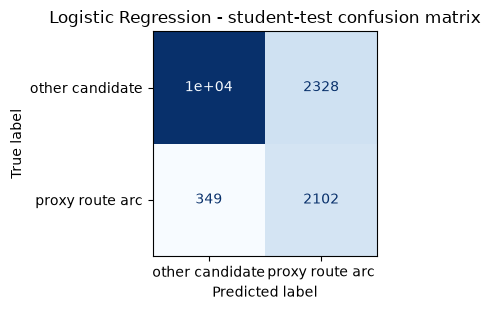

In [4]:
from sklearn.linear_model import LogisticRegression
logistic_model = evaluate_one_model("Logistic Regression", LogisticRegression(max_iter=400, class_weight="balanced", random_state=42))

## Model 2: Gaussian Naive Bayes

Gaussian Naive Bayes | GaussianNB()


,Metric,Value
0,Training macro F1,0.7734
1,Grouped CV macro F1,0.7732
2,Student candidate accuracy,0.8993
3,Student candidate precision (positive class),0.7683
4,Student candidate recall (positive class),0.5492
5,Student candidate macro F1,0.7910
6,Student candidate log loss,0.2469
7,Observation Top-1 proxy accuracy,0.7632
8,Candidate miss rate,0.0196
9,Continuity before Viterbi,0.5968


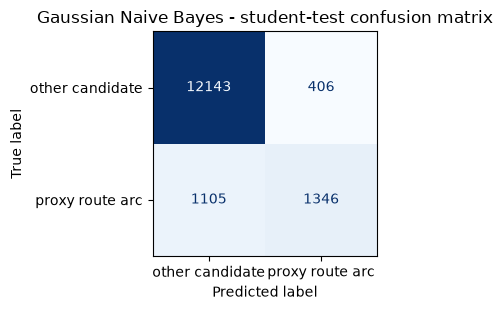

In [5]:
from sklearn.naive_bayes import GaussianNB
naive_bayes_model = evaluate_one_model("Gaussian Naive Bayes", GaussianNB())

## Model 3: Decision Tree

Decision Tree | DecisionTreeClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=15, random_state=42)


,Metric,Value
0,Training macro F1,0.7870
1,Grouped CV macro F1,0.7379
2,Student candidate accuracy,0.8357
3,Student candidate precision (positive class),0.4984
4,Student candidate recall (positive class),0.8360
5,Student candidate macro F1,0.7597
6,Student candidate log loss,0.4745
7,Observation Top-1 proxy accuracy,0.7164
8,Candidate miss rate,0.0196
9,Continuity before Viterbi,0.5787


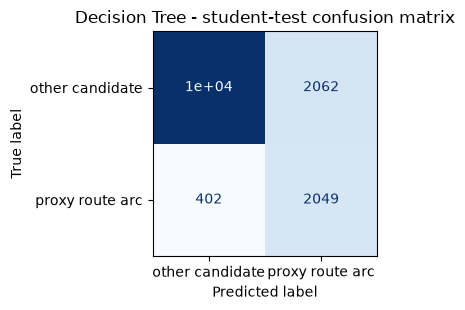

In [6]:
from sklearn.tree import DecisionTreeClassifier
tree_model = evaluate_one_model("Decision Tree", DecisionTreeClassifier(max_depth=12, min_samples_leaf=15, class_weight="balanced", random_state=42))

## Model 4: Random Forest

Random Forest | RandomForestClassifier(class_weight='balanced_subsample', max_depth=14,
                       min_samples_leaf=8, n_estimators=60, n_jobs=-1,
                       random_state=42)


,Metric,Value
0,Training macro F1,0.8292
1,Grouped CV macro F1,0.7832
2,Student candidate accuracy,0.8773
3,Student candidate precision (positive class),0.5898
4,Student candidate recall (positive class),0.8184
5,Student candidate macro F1,0.8047
6,Student candidate log loss,0.2879
7,Observation Top-1 proxy accuracy,0.7436
8,Candidate miss rate,0.0196
9,Continuity before Viterbi,0.6008


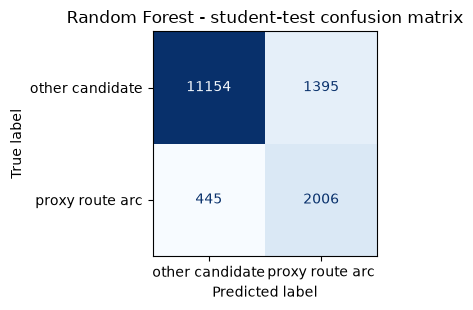

In [7]:
from sklearn.ensemble import RandomForestClassifier
forest_model = evaluate_one_model("Random Forest", RandomForestClassifier(n_estimators=60, max_depth=14, min_samples_leaf=8, class_weight="balanced_subsample", n_jobs=-1, random_state=42))

## Model 5: Histogram Gradient Boosting

Histogram Gradient Boosting | HistGradientBoostingClassifier(l2_regularization=0.1, max_iter=80,
                               max_leaf_nodes=25, random_state=42)


,Metric,Value
0,Training macro F1,0.7992
1,Grouped CV macro F1,0.7876
2,Student candidate accuracy,0.9048
3,Student candidate precision (positive class),0.7598
4,Student candidate recall (positive class),0.6104
5,Student candidate macro F1,0.8105
6,Student candidate log loss,0.2279
7,Observation Top-1 proxy accuracy,0.7504
8,Candidate miss rate,0.0196
9,Continuity before Viterbi,0.6076


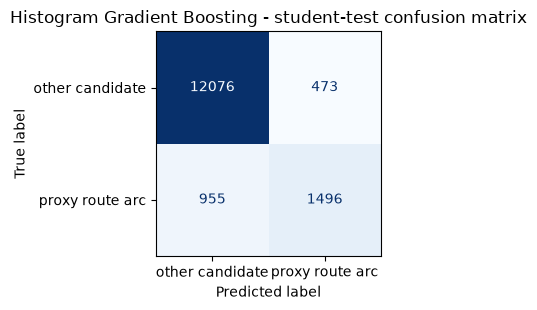

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
hist_model = evaluate_one_model("Histogram Gradient Boosting", HistGradientBoostingClassifier(max_iter=80, max_leaf_nodes=25, l2_regularization=0.1, random_state=42))

## Conclusion and integrity note

Histogram Gradient Boosting had the strongest sampled **after-Viterbi** proxy pointwise accuracy among the five initial models. Gaussian Naive Bayes had a slightly stronger classifier-only Top-1 score, so report both. The training script separately performs Bayesian tuning on the selected model; its saved results are in `artifacts/experiment_results.json`.

The reserved evaluator trips are not used here. These pointwise labels are derived from reference routes and should not be described as independently verified ground truth. Training and inference times can vary across machines.

## Final model evaluation and comparison

This final cell compares all five models using the same metrics. The five model cells above contain the evaluation code, metrics, plots, and confusion matrices. The final family is selected using grouped **training CV macro F1**; student-test route metrics are reported separately.

**Route continuity** is the share of consecutive predicted arcs that either stay on the same arc or meet at a directed road node. Before Viterbi, each GPS point independently takes its highest-scoring candidate, which can jump between disconnected roads. Viterbi scores the entire sequence and penalizes disconnected transitions, so it usually improves continuity. A remaining gap is possible because the decoder permits a penalized fallback when GPS points or road candidates are missing.

,Candidate accuracy,Precision,Recall,Candidate macro F1,CV macro F1,Log loss,Top-1 GPS accuracy,After-Viterbi GPS accuracy,Route continuity before Viterbi (%),Route continuity after Viterbi (%),Continuity gain (percentage points),Candidate miss rate,Training seconds including CV,Model scoring seconds
Logistic Regression,0.8215,0.4745,0.8576,0.7476,0.7408,0.3877,0.7588,0.7384,59.3574,75.3414,15.9839,0.0196,0.6318,0.0075
Gaussian Naive Bayes,0.8993,0.7683,0.5492,0.7910,0.7732,0.2469,0.7632,0.7580,59.6787,72.5301,12.8514,0.0196,0.1188,0.0139
Decision Tree,0.8357,0.4984,0.8360,0.7597,0.7379,0.4745,0.7164,0.7216,57.8715,71.1245,13.2530,0.0196,1.7144,0.0078
Random Forest,0.8773,0.5898,0.8184,0.8047,0.7832,0.2879,0.7436,0.7544,60.0803,73.5341,13.4538,0.0196,13.8929,0.4754
Histogram Gradient Boosting,0.9048,0.7598,0.6104,0.8105,0.7876,0.2279,0.7504,0.7640,60.7631,72.0080,11.2450,0.0196,8.9558,0.2823


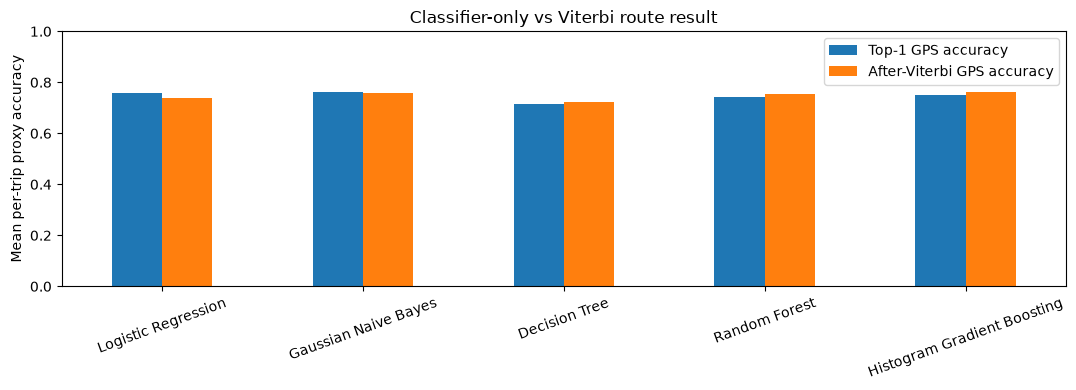

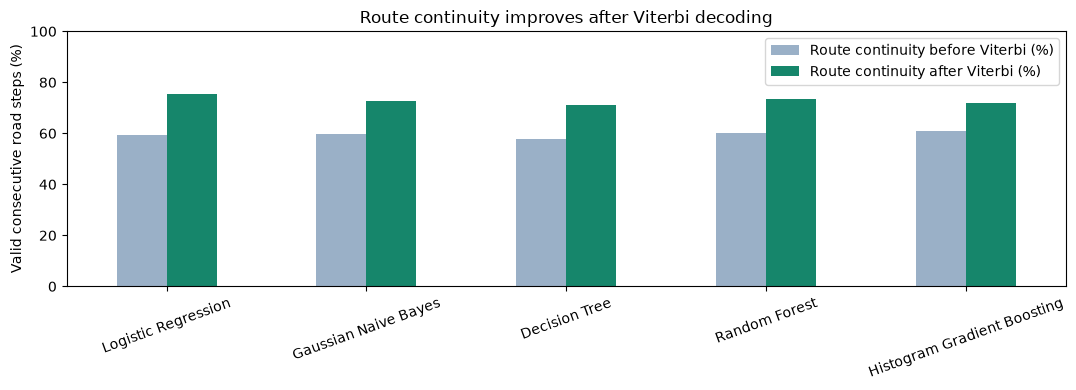

In [9]:
summary = pd.DataFrame({name: {
    "Candidate accuracy": m["candidate_accuracy"],
    "Precision": m["precision"],
    "Recall": m["recall"],
    "Candidate macro F1": m["candidate_macro_f1"],
    "CV macro F1": m["cv_macro_f1_mean"],
    "Log loss": m["log_loss"],
    "Top-1 GPS accuracy": m["mean_trip_top1_accuracy"],
    "After-Viterbi GPS accuracy": m["mean_trip_accuracy_viterbi"],
    "Route continuity before Viterbi (%)": 100 * m["mean_continuity_classifier"],
    "Route continuity after Viterbi (%)": 100 * m["mean_continuity_viterbi"],
    "Continuity gain (percentage points)": 100 * (m["mean_continuity_viterbi"] - m["mean_continuity_classifier"]),
    "Candidate miss rate": m["mean_candidate_miss_rate"],
    "Training seconds including CV": m["training_seconds_including_cv"],
    "Model scoring seconds": m["inference_seconds_total"],
} for name, m in model_results.items()}).T
display(summary.style.format("{:.4f}"))
ax = summary[["Top-1 GPS accuracy", "After-Viterbi GPS accuracy"]].plot.bar(figsize=(11, 4), ylim=(0, 1), rot=20)
ax.set_ylabel("Mean per-trip proxy accuracy")
ax.set_title("Classifier-only vs Viterbi route result")
plt.tight_layout()
plt.show()
ax = summary[["Route continuity before Viterbi (%)", "Route continuity after Viterbi (%)"]].plot.bar(figsize=(11, 4), ylim=(0, 100), rot=20, color=["#9ab0c7", "#16866b"])
ax.set_ylabel("Valid consecutive road steps (%)")
ax.set_title("Route continuity improves after Viterbi decoding")
plt.tight_layout()
plt.show()